# M5.6 · 多期 Brinson 与几何链接

> 单期 Brinson 的配置/选股/交互是算术收益，多期直接相加会因复利而对不上总超额。
> 需用链接系数把各期效应折算到同一（对数）收益空间，保证多期归因闭合。

## 一、为什么需要链接

- 单期算术超额 $a_t=R_t-B_t$，多期总超额是几何（复利）结果，$\sum a_t \neq$ 几何超额；
- **Cariño（1999）系数**：
$$k_t=\frac{R_t-B_t}{\ln(1+R_t)-\ln(1+B_t)},\qquad
\text{链接效应}=\frac{\text{单期效应}}{k_t}$$
- 各期链接效应之和 = 对数几何超额，实现闭合；$R_t=B_t$ 时 $k_t$ 取极限 $1+R_t$。

## 二、多期链接算例

In [1]:
import sys
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import numpy as np, pandas as pd
from bt_lab2 import brinson_link as bl
rng = np.random.default_rng(1); T = 12
pe = rng.normal(0.001, 0.01, T); be = rng.normal(0.0008, 0.009, T)
alloc = rng.normal(0, 0.001, T); sel = rng.normal(0.001, 0.002, T)
inter = (pe - be) - alloc - sel                 # 单期 BHB 恒等
eff = pd.DataFrame({'配置': alloc, '选股': sel, '交互': inter})
res = bl.link_multi_period(eff, pe, be)
print('对数几何超额=%.5f' % res['log_excess'])
print('闭合残差=%.2e（应≈0）' % res['closure_residual'])
print('链接后各效应合计:'); print(res['summary'].round(5))

对数几何超额=0.03093
闭合残差=-3.50e-16（应≈0）
链接后各效应合计:
配置   -0.00078
选股    0.00144
交互    0.03027
dtype: float64


## 三、可视化

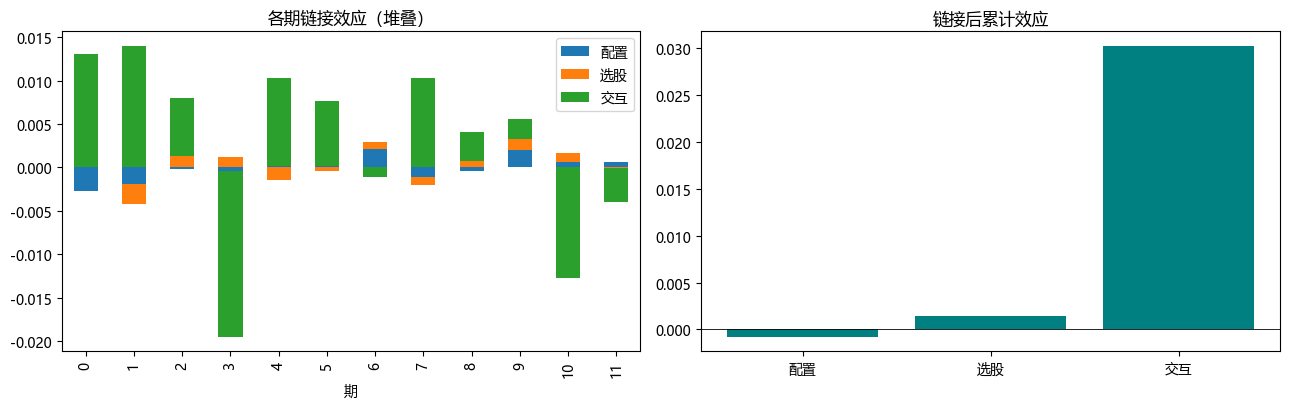

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
res['linked'].plot(kind='bar', stacked=True, ax=ax[0])
ax[0].set_title('各期链接效应（堆叠）'); ax[0].set_xlabel('期')
ax[1].bar(res['summary'].index, res['summary'].values, color='teal')
ax[1].set_title('链接后累计效应'); ax[1].axhline(0, color='k', lw=0.6)
plt.tight_layout(); plt.show()

## 四、面试要点

- **算术归因为何不能直接跨期相加？** 各期效应基于不同的本金基数，复利使简单加总偏离真实总超额。
- **Cariño 系数的作用？** 把单期算术效应折算为对数（可加）效应，折算后加总恰为对数几何超额。
- **如何验证归因闭合？** 链接后全部效应之和应等于组合与基准累计净值的对数差，残差应接近 0。
- **还有哪些链接方法？** Cariño 对数链接、几何超额链接（BFG）等，核心都是消除复利造成的口径差。

## 五、练习

1. 用真实行业分组构造多期 Brinson 再链接。
2. 验证不做链接时的加总误差有多大。
3. 改变期数，检验闭合残差是否始终接近 0。
4. 推导 Cariño 系数在 R=B 处的极限。